# 04 · VLM labeling: score the "ground-level ride experience" of street photos with Gemini (GreenPath)

**What this step does**: this is the "teacher" part. Gemini looks at every street photo and, following fixed scoring rules, scores 8 dimensions from 1 to 5; the scores are then aggregated per cell to give the training labels **Y**.

| Dimension | Meaning |
|---|---|
| `traffic_intensity` | Amount of motor traffic |
| `quietness` | How quiet it is |
| `shade` | Overhead shade or cover for the rider |
| `naturalness` | How natural the surroundings feel |
| `scenic_appeal` | Overall scenic appeal |
| `historic_character` | Historic character |
| `liveliness` | Street life and activity |
| `visual_openness` | How open the view is |

| | Path (relative to the data root) |
|---|---|
| Input: selected street photos | `processed/streetview.parquet`, `raw/mapillary/images/` |
| Input: scoring rules | `prompts/{version}.txt` (in the project directory, not the data directory) |
| Output: score of every photo (cache) | `processed/labels_image.parquet` |
| Output: **label Y of every cell** | `processed/labels_cell.parquet` |
| Output: labeling metadata (model, prompt version, cost) | `processed/labels_meta.json` |
| Output: **gallery (browse all photos and scores)** | `processed/labels_gallery.html` (open in a browser) |
| Output: photos and sheet for human annotation | `processed/qa/human_images/`, `processed/qa/human_label_sheet.csv` |
| Output: run record | `runs/{timestamp}/04_labeling_manifest.json` |

**How to use**
1. Finish the Vertex AI setup first (checklist in section 2), and continue only after the section 4 "smoke test" passes.
2. Section 5, the **prompt sandbox**: look at the scores and rationales of 8 photos; if you are not satisfied, edit the rules in `prompts/` and **bump the version number** (`v1` → `v2`); labels of the old version are not overwritten.
3. Section 6 scores everything in batch. Results are cached by `(photo, prompt version, model)`, so **photos that were already scored are not called again and cost nothing again**; you can safely resume or scale up the sample.

**This costs money**: one Gemini call per photo. The cost per photo is estimated at the end of section 4, and the actual total is summed up at the end of section 6.

## 1. Install dependencies (runs only on Colab)

In [1]:
import sys, subprocess
if "google.colab" in sys.modules:      # Install automatically only on Colab; locally, install the dependencies beforehand
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "google-genai", "pydantic", "h3>=4", "pandas", "pyarrow", "gcsfs", "matplotlib", "pillow", "scipy", "tqdm", "fsspec"], check=True)

## 2. Configuration
**Vertex AI setup checklist (once only)**
1. Create a project in the GCP console and link a billing account (course credit or trial credit).
2. Enable the **Vertex AI API**.
3. Install the gcloud CLI (Mac: `brew install --cask google-cloud-sdk`) and run `gcloud auth application-default login`.
4. Add two lines to `.env` in the project root: `GOOGLE_CLOUD_PROJECT=your-project-id` and `GOOGLE_CLOUD_LOCATION=us-central1`.
5. Set `MODEL` to a Gemini model that is available in Model Garden; a 404 means the model is not available in your region.

**Parameters**
- `PROMPT_VERSION`: which version of the scoring rules to use (`prompts/{version}.txt`). When you change the rules, bump the version number.
- `THINKING_BUDGET`: some Gemini models "think" first by default, which costs extra tokens; `0` = off (scoring does not need it), `None` = do not send this parameter (use it when the model does not support it).
- `MIN_USABLE_IMAGES`: how many usable photos a cell needs before it gets a label; otherwise it is marked missing (NaN) and skipped in training.
- `MAX_IMAGES`: the maximum number of new photos to score in this run (`None` = all). For the first run, try about 50.
- `THUMB_PX` / `GALLERY_MAX_IMAGES`: thumbnail size in the gallery, and the maximum number of photos put in it.
- `PRICE_*`: price per million tokens (USD), used only to estimate cost. **Please check against the official pricing page.**

In [2]:
PROMPT_VERSION = "v2"
PROMPT_DIR = "prompts"
MODEL = "gemini-2.5-flash"      # use whichever model is actually available in Vertex AI Model Garden
THINKING_BUDGET = 0             # 0 turns thinking off; None omits this parameter

WORKERS = 8
MIN_USABLE_IMAGES = 2
MAX_IMAGES = None               # e.g. 50: score at most 50 new photos in this run
SANDBOX_N = 8                   # how many photos the prompt sandbox shows
QA_N = 150                      # number of photos exported for human annotation
THUMB_PX = 480                  # longest side of the thumbnails in the gallery (pixels)
GALLERY_MAX_IMAGES = 1000       # maximum number of photos in the gallery; None = all
SEED = 42

PRICE_IN_PER_M = 0.30           # USD per million input tokens (check the official pricing)
PRICE_OUT_PER_M = 2.50          # USD per million output tokens (check the official pricing)

STORAGE = "local"                              # "local" | "gcs" | "drive"
GCS_ROOT = "gs://greenpath-data"
DRIVE_ROOT = "/content/drive/MyDrive/greenpath-data"
LOCAL_ROOT = "./data"

## 3. Connect to storage and read the project configuration

In [3]:
import os, io, json, datetime
import fsspec
import pandas as pd

STORAGE_OPTS = {}
if STORAGE == "gcs":
    try:
        from google.colab import auth
        auth.authenticate_user()                 # On Colab, log in here; locally, first run gcloud auth application-default login
    except ImportError:
        pass
    ROOT = GCS_ROOT
    STORAGE_OPTS = {"token": "google_default"}
    fs = fsspec.filesystem("gcs", **STORAGE_OPTS)
elif STORAGE == "drive":
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = DRIVE_ROOT
    fs = fsspec.filesystem("file")
else:
    ROOT = os.environ.get("GREENPATH_ROOT", LOCAL_ROOT)   # later, containers can set the data directory through an environment variable
    fs = fsspec.filesystem("file")

def path(*parts):
    # build the full path under the data root, e.g. path("processed", "cells.parquet")
    return "/".join([ROOT.rstrip("/"), *parts])

def makedirs(p):
    if STORAGE != "gcs":            # GCS has no real directories, so there is nothing to create
        os.makedirs(p, exist_ok=True)

def read_parquet(p):
    return pd.read_parquet(p, storage_options=STORAGE_OPTS or None)

def write_parquet(df, p):
    df.to_parquet(p, index=False, storage_options=STORAGE_OPTS or None)

def write_manifest(manifest, name):
    run_ts = datetime.datetime.utcnow().strftime("%Y-%m-%dT%H-%M")
    makedirs(path("runs", run_ts))
    with fs.open(path("runs", run_ts, name), "w") as f:
        json.dump(manifest, f, indent=2, ensure_ascii=False)
    return manifest

try:                                          # use a system CJK font so any CJK text in charts renders correctly
    import matplotlib
    matplotlib.rcParams["font.sans-serif"] = ["PingFang SC", "Heiti SC", "Arial Unicode MS", "Noto Sans CJK SC",
                                              "Microsoft YaHei", "SimHei", "DejaVu Sans"]
    matplotlib.rcParams["axes.unicode_minus"] = False
except ImportError:
    pass

now_iso = lambda: datetime.datetime.utcnow().isoformat(timespec="seconds") + "Z"
print("Data root:", ROOT)

Data root: ./data


In [4]:
import numpy as np, hashlib, random, threading, time
from concurrent.futures import ThreadPoolExecutor, as_completed
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

def load_dotenv_file(name=".env"):
    # Search upward from the current directory for .env and load its KEY=VALUE lines into the environment (variables that are already set take precedence)
    d = os.path.abspath(os.getcwd())
    while True:
        p = os.path.join(d, name)
        if os.path.isfile(p):
            for line in open(p, encoding="utf-8"):
                line = line.strip()
                if line and not line.startswith("#") and "=" in line:
                    k, v = line.split("=", 1)
                    os.environ.setdefault(k.strip(), v.strip().strip("\"'"))
            return p
        if os.path.dirname(d) == d:
            return None
        d = os.path.dirname(d)

load_dotenv_file()
PROJECT = os.environ.get("GOOGLE_CLOUD_PROJECT")
LOCATION = os.environ.get("GOOGLE_CLOUD_LOCATION", "us-central1")
assert PROJECT, "GOOGLE_CLOUD_PROJECT not found: add GOOGLE_CLOUD_PROJECT=your-project-id to .env (see the checklist in section 2)"

DIMS = ["traffic_intensity", "quietness", "shade", "naturalness",
        "scenic_appeal", "historic_character", "liveliness", "visual_openness"]

sv = read_parquet(path("processed", "streetview.parquet"))
if "downloaded" in sv:                                  # photos that failed to download in 01 have no file; skip them
    sv = sv[sv.downloaded.astype(bool)].reset_index(drop=True)
cells = read_parquet(path("processed", "cells.parquet"))
print(f"Project {PROJECT} · region {LOCATION} · model {MODEL}")
print(f"To process: {len(sv)} street photos, {sv.cell_id.nunique()} cells")

Project organic-victory-508017-v9 · region us-central1 · model gemini-2.5-flash
To process: 4421 street photos, 1126 cells


## 4. Connect to Vertex AI + smoke test
`call_model` is **the only place in the whole notebook that calls Gemini directly**. The smoke test scores one photo; if it fails, it tells you which kind of problem it is:

| Error | Common cause |
|---|---|
| 401 | Not logged in: run `gcloud auth application-default login` |
| 403 | The project has not enabled the Vertex AI API, has no billing, or the account lacks permission |
| 404 | This model is not available in this region: change `MODEL` or `GOOGLE_CLOUD_LOCATION` |
| 400 | A parameter is not supported: first try setting `THINKING_BUDGET` to `None` |
| 429 | Requests are too fast (quota): lower `WORKERS` |

In [5]:
import json
from pydantic import BaseModel
from google import genai
from google.genai import types, errors as genai_errors

class Scores(BaseModel):
    traffic_intensity: int
    quietness: int
    shade: int
    naturalness: int
    scenic_appeal: int
    historic_character: int
    liveliness: int
    visual_openness: int

class ImageLabel(BaseModel):
    usable: bool
    unusable_reason: str
    scores: Scores
    rationale: str

PROMPT = open(os.path.join(PROMPT_DIR, f"{PROMPT_VERSION}.txt"), encoding="utf-8").read()
PROMPT_SHA = hashlib.sha256(PROMPT.encode()).hexdigest()[:12]

client = genai.Client(vertexai=True, project=PROJECT, location=LOCATION)

def call_model(img_bytes):
    # returns (the JSON text of the reply, number of input tokens, number of output tokens)
    cfg = dict(temperature=0.0, response_mime_type="application/json",
               response_schema=ImageLabel, max_output_tokens=2048)
    if THINKING_BUDGET is not None:
        cfg["thinking_config"] = types.ThinkingConfig(thinking_budget=THINKING_BUDGET)
    resp = client.models.generate_content(
        model=MODEL,
        contents=[types.Part.from_bytes(data=img_bytes, mime_type="image/jpeg"), PROMPT],
        config=types.GenerateContentConfig(**cfg))
    u = resp.usage_metadata
    tin = (u.prompt_token_count or 0) if u else 0
    tout = ((u.candidates_token_count or 0) + (getattr(u, "thoughts_token_count", 0) or 0)) if u else 0
    return resp.text, tin, tout

FATAL_HINTS = {
    400: "A parameter is not supported: try setting THINKING_BUDGET to None first",
    401: "Not logged in: run gcloud auth application-default login",
    403: "The project has not enabled the Vertex AI API, has no billing linked, or the account lacks permission",
    404: "This model is not available in this region: change MODEL or GOOGLE_CLOUD_LOCATION",
}

class FatalAPIError(RuntimeError):
    pass

def check_label(label):
    sc = label.scores.model_dump()
    if label.usable:
        bad = {k: v for k, v in sc.items() if not 1 <= v <= 5}
        if bad:
            raise ValueError(f"Scores of a usable photo must be between 1 and 5: {bad}")
    else:
        sc = {k: 0 for k in sc}
    return sc

def score_image(image_id, rel_path, tries=5):
    with fs.open(path(rel_path), "rb") as f:
        data = f.read()
    last = None
    for k in range(tries):
        try:
            text, tin, tout = call_model(data)
            label = ImageLabel.model_validate_json(text)
            sc = check_label(label)
            return {"image_id": image_id, "prompt_version": PROMPT_VERSION, "prompt_sha": PROMPT_SHA,
                    "model": MODEL, "usable": bool(label.usable),
                    "unusable_reason": label.unusable_reason, **sc,
                    "rationale": label.rationale, "input_tokens": tin, "output_tokens": tout,
                    "scored_at": now_iso()}
        except genai_errors.APIError as e:
            if e.code in FATAL_HINTS:
                raise FatalAPIError(f"Vertex AI returned {e.code}: {FATAL_HINTS[e.code]}\nOriginal message: {str(e)[:300]}")
            last = e
            time.sleep(min(60, 2 ** k + random.random()))      # 429 / 5xx: back off and retry
        except ValueError as e:                                  # the returned JSON is not in the expected format
            last = e
            time.sleep(1)
    raise RuntimeError(f"Still failing after {tries} retries: {last!r}"[:300])

def cost_usd(tin, tout):
    return tin / 1e6 * PRICE_IN_PER_M + tout / 1e6 * PRICE_OUT_PER_M

first = sv.iloc[0]
row = score_image(first.image_id, first.image_path)
print(json.dumps({k: row[k] for k in ["usable", "unusable_reason", *DIMS, "rationale"]}, ensure_ascii=False, indent=2))
print(f"This photo: input {row['input_tokens']} / output {row['output_tokens']} tokens, about ${cost_usd(row['input_tokens'], row['output_tokens']):.5f}"
      f" → estimated {len(sv)} photos at about ${cost_usd(row['input_tokens'], row['output_tokens']) * len(sv):.2f}")

{
  "usable": true,
  "unusable_reason": "",
  "traffic_intensity": 3,
  "quietness": 3,
  "shade": 3,
  "naturalness": 3,
  "scenic_appeal": 3,
  "historic_character": 3,
  "liveliness": 3,
  "visual_openness": 3,
  "rationale": "The street has some traffic, a mix of buildings and trees, and a moderate view, creating an ordinary urban cycling experience."
}
This photo: input 2236 / output 137 tokens, about $0.00101 → estimated 4421 photos at about $4.48


## 5. Prompt sandbox
Randomly picks `SANDBOX_N` photos and shows the image, the 8 scores, and the rationale Gemini gave. **The results here are not written to the cache**; this section exists to refine the scoring rules.
What to look for:
- Are the scores always bunched at 3? (Bunching in the middle means the anchors do not discriminate well enough.)
- Does the rationale agree with your own judgment?
- Are the photos that should be marked "unusable" (blurred, etc.) actually flagged?

If you are not satisfied, edit `prompts/{version}.txt`, **bump the version number** (change `PROMPT_VERSION`), and rerun section 4 and this section.

sandbox:   0%|          | 0/8 [00:00<?, ?it/s]

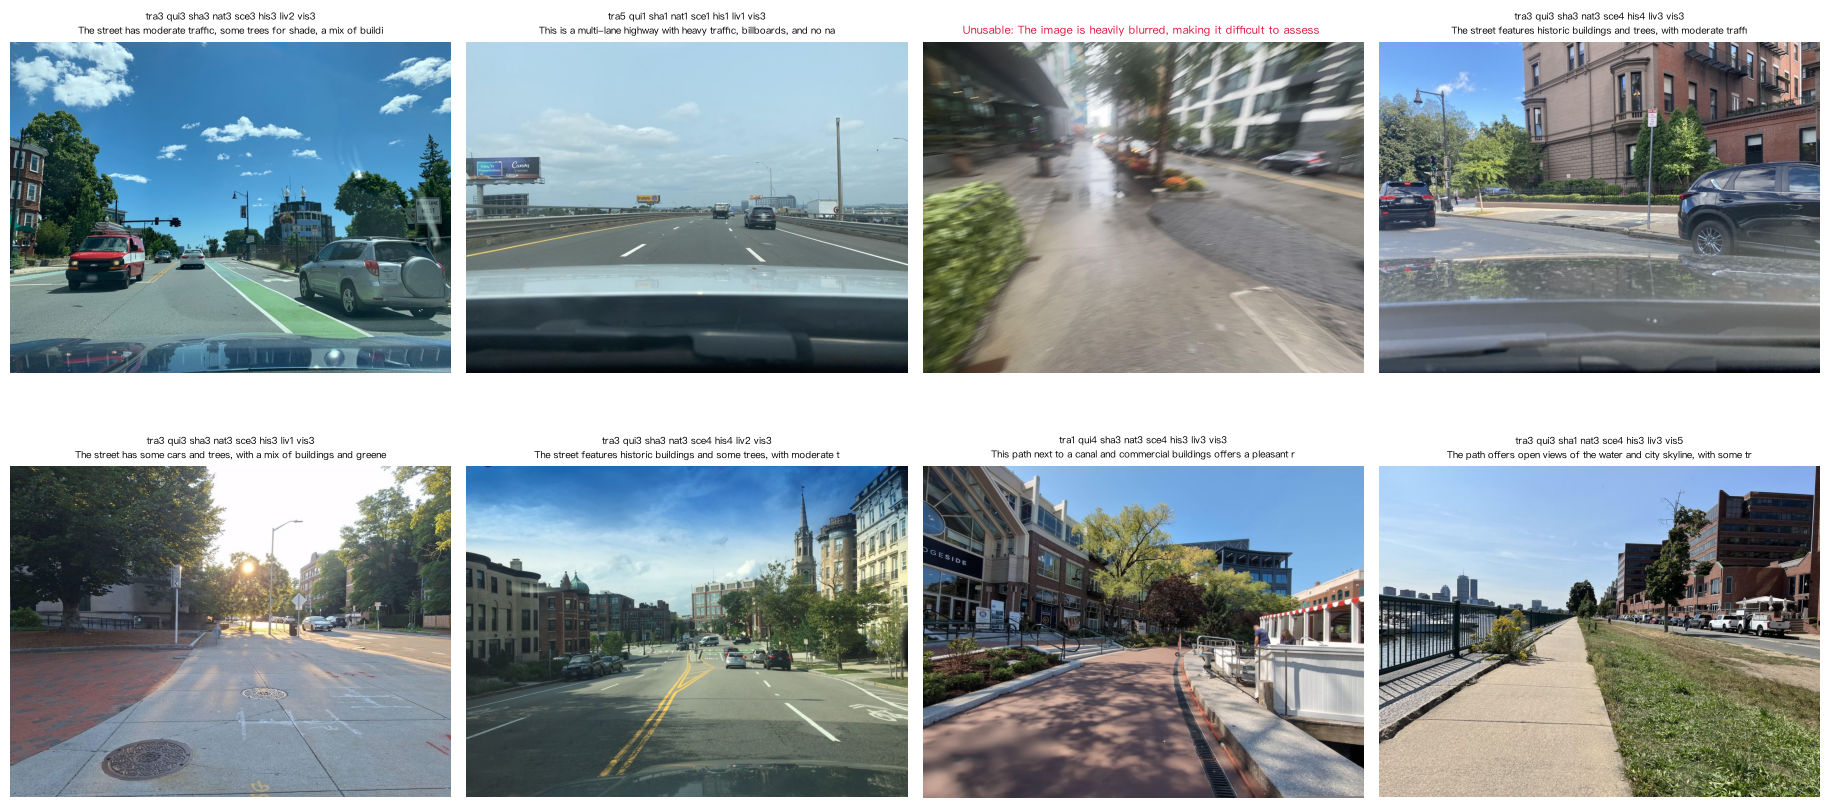

In [6]:
sample = sv.sample(n=min(SANDBOX_N, len(sv)), random_state=SEED)
items = list(sample.itertuples())

def try_score(r):
    try:
        return r, score_image(r.image_id, r.image_path)
    except Exception as e:
        print("  failed:", r.image_id, repr(e)[:150])
        return None

with ThreadPoolExecutor(max_workers=WORKERS) as ex:                # parallel calls, 8 photos take about ten seconds
    rows = [x for x in tqdm(ex.map(try_score, items), total=len(items), desc="sandbox") if x]

ncol = 4; nrow = max(int(np.ceil(len(rows) / ncol)), 1)
fig, axes = plt.subplots(nrow, ncol, figsize=(4.6 * ncol, 4.6 * nrow))
for ax in np.atleast_1d(axes).ravel():
    ax.axis("off")
for ax, (r, lab) in zip(np.atleast_1d(axes).ravel(), rows):
    with fs.open(path(r.image_path), "rb") as f:
        ax.imshow(Image.open(f))
    if lab["usable"]:
        s = " ".join(f"{d[:3]}{lab[d]}" for d in DIMS)
        ax.set_title(f"{s}\n{lab['rationale'][:70]}", fontsize=7)
    else:
        ax.set_title(f"Unusable: {lab['unusable_reason'][:60]}", fontsize=8, color="crimson")
plt.tight_layout(); plt.show()

## 6. Batch scoring
- Only photos that are **not cached yet** are processed (cache key: photo + prompt version + model).
- `WORKERS` threads run in parallel; progress is saved every 50 photos, so an interruption (even Ctrl-C) does not lose results.
- A single failure is only recorded and does not stop the batch; **systematic errors such as authentication / permission / model problems stop immediately**, to avoid wasting hundreds of calls.

In [7]:
from concurrent.futures import ThreadPoolExecutor, as_completed

LABELS_REL = "processed/labels_image.parquet"
LABEL_COLS = ["image_id", "prompt_version", "prompt_sha", "model", "usable", "unusable_reason", *DIMS,
              "rationale", "input_tokens", "output_tokens", "scored_at"]

def load_cache():
    p = path(LABELS_REL)
    return read_parquet(p) if fs.exists(p) else pd.DataFrame(columns=LABEL_COLS)

cache = load_cache()
done = set(cache[(cache.prompt_version == PROMPT_VERSION) & (cache.model == MODEL)].image_id)
todo = sv[~sv.image_id.isin(done)]
if MAX_IMAGES:
    todo = todo.head(MAX_IMAGES)
print(f"{len(done)} photos already cached; {len(todo)} new photos to score in this run")

new_rows, errors, abort = [], {}, threading.Event()

def save_progress():
    global cache
    if new_rows:
        cache = pd.concat([cache, pd.DataFrame(new_rows, columns=LABEL_COLS)], ignore_index=True) \
                  .drop_duplicates(["image_id", "prompt_version", "model"], keep="last")
        write_parquet(cache, path(LABELS_REL))
        new_rows.clear()

def work(r):
    if abort.is_set():
        return None
    return score_image(r.image_id, r.image_path)

fatal = None
try:
    with ThreadPoolExecutor(max_workers=WORKERS) as ex:
        futs = {ex.submit(work, r): r for r in todo.itertuples()}
        for k, fut in enumerate(tqdm(as_completed(futs), total=len(futs), desc="scoring"), 1):
            r = futs[fut]
            try:
                row = fut.result()
                if row:
                    new_rows.append(row)
            except FatalAPIError as e:
                fatal = e; abort.set()
            except Exception as e:
                errors[r.image_id] = repr(e)[:200]
            if k % 50 == 0:
                save_progress()
finally:
    save_progress()

mine = cache[(cache.prompt_version == PROMPT_VERSION) & (cache.model == MODEL)]
print(f"The cache now holds {len(mine)} photos ({int(mine.usable.sum())} usable, {int((~mine.usable.astype(bool)).sum())} unusable); {len(errors)} failed in this run")
tin, tout = int(mine.input_tokens.sum()), int(mine.output_tokens.sum())
print(f"Cumulative tokens: input {tin:,} / output {tout:,}, estimated cumulative cost about ${cost_usd(tin, tout):.3f}")
if errors:
    print("Failure examples:", list(errors.items())[:3])
if fatal:
    raise fatal

4421 photos already cached; 0 new photos to score in this run


scoring: 0it [00:00, ?it/s]

The cache now holds 4421 photos (4340 usable, 81 unusable); 0 failed in this run
Cumulative tokens: input 10,505,072 / output 557,698, estimated cumulative cost about $4.546


## 7. Aggregate per cell → labels Y
- Only **usable** photos are used; for each dimension the mean over the cell is taken, together with the standard deviation (how much the cell's photos disagree) and the number of photos.
- Normalized to 0–1: `(score − 1) / 4`.
- Cells with fewer than `MIN_USABLE_IMAGES` usable photos get the label `NaN` (missing): training skips it with a masked loss instead of treating it as 0.

In [8]:
mine = cache[(cache.prompt_version == PROMPT_VERSION) & (cache.model == MODEL)].copy()
mine["usable"] = mine.usable.astype(bool)
for d in DIMS:
    mine[d] = pd.to_numeric(mine[d])
lab = mine.merge(sv[["image_id", "cell_id", "h3_index"]], on="image_id", how="inner")
ok = lab[lab.usable]

g = ok.groupby(["cell_id", "h3_index"])
agg = g[DIMS].mean().add_suffix("_mean").join(g[DIMS].std(ddof=0).add_suffix("_std")).join(g.size().rename("n_usable")).reset_index()
labels_cell = cells[["cell_id", "h3_index"]].merge(agg, on=["cell_id", "h3_index"], how="left")
labels_cell["n_images"] = labels_cell.cell_id.map(sv.groupby("cell_id").size()).fillna(0).astype(int)
labels_cell["n_usable"] = labels_cell.n_usable.fillna(0).astype(int)
enough = labels_cell.n_usable >= MIN_USABLE_IMAGES
for d in DIMS:
    labels_cell[d] = ((labels_cell[f"{d}_mean"] - 1) / 4).where(enough)          # normalize to 0–1
    labels_cell[f"{d}_std"] = (labels_cell[f"{d}_std"] / 4).where(enough)
labels_cell = labels_cell[["cell_id", "h3_index", "n_images", "n_usable", *DIMS, *[f"{d}_std" for d in DIMS]]]
labels_cell["prompt_version"] = PROMPT_VERSION
labels_cell["model"] = MODEL
write_parquet(labels_cell, path("processed", "labels_cell.parquet"))

meta = {"model": MODEL, "prompt_version": PROMPT_VERSION, "prompt_sha": PROMPT_SHA, "location": LOCATION,
        "thinking_budget": THINKING_BUDGET, "temperature": 0.0, "min_usable_images": MIN_USABLE_IMAGES,
        "images_scored": int(len(mine)), "images_usable": int(mine.usable.sum()),
        "input_tokens": int(mine.input_tokens.sum()), "output_tokens": int(mine.output_tokens.sum()),
        "est_cost_usd": round(cost_usd(int(mine.input_tokens.sum()), int(mine.output_tokens.sum())), 4),
        "cells_total": int(len(labels_cell)), "cells_labeled": int(enough.sum()), "created_at": now_iso()}
with fs.open(path("processed", "labels_meta.json"), "w") as f:
    json.dump(meta, f, indent=2, ensure_ascii=False)
print(f"labels_cell.parquet: {len(labels_cell)} cells, of which {int(enough.sum())} have labels (usable photos ≥ {MIN_USABLE_IMAGES})")
labels_cell[DIMS].describe().T[["count", "mean", "std", "min", "max"]].round(2)

labels_cell.parquet: 1126 cells, of which 1116 have labels (usable photos ≥ 2)


,count,mean,std,min,max
traffic_intensity,1116.0,0.55,0.22,0.0,1.00
quietness,1116.0,0.41,0.20,0.0,1.00
shade,1116.0,0.26,0.25,0.0,1.00
naturalness,1116.0,0.27,0.21,0.0,1.00
scenic_appeal,1116.0,0.44,0.22,0.0,1.00
historic_character,1116.0,0.38,0.28,0.0,1.00
liveliness,1116.0,0.21,0.18,0.0,0.75
visual_openness,1116.0,0.50,0.11,0.0,1.00


## 8. Gallery: browse all photos and detailed scores
Generates a **single-file HTML** (`processed/labels_gallery.html`) that opens directly in a browser, no kernel needed:
- One card per photo: thumbnail (an embedded small image of `THUMB_PX` pixels, **click to open the original**), score bars for the 8 dimensions, Gemini's rationale, the cell, capture date, and heading.
- **Filter**: usable / unusable only; search by cell; filter by the score range of one dimension (for example all photos with "shade = 1", to check that they really have no trees).
- **Sort**: by one dimension, high→low or low→high; group by cell so that the photos of one place sit side by side and you can see how much they disagree.
- **Version comparison**: if the same photo was also scored under another prompt version or model, the card can be expanded to compare.
- Because the thumbnails are embedded, this file can be sent straight to teammates; clicking through to the original requires the HTML and the `data/` directory to stay in their original place on the same machine (local storage mode).

`GALLERY_MAX_IMAGES`: the maximum number of photos to include (a random subset is taken above that). Each thumbnail is about 30 KB, so 1,000 photos are about 30 MB, which a browser still opens smoothly; `None` = all.

In [9]:
import base64, io as _io
from concurrent.futures import ThreadPoolExecutor

GALLERY_REL = "processed/labels_gallery.html"
SHORT = {"traffic_intensity": "Traffic", "quietness": "Quiet", "shade": "Shade", "naturalness": "Nature",
         "scenic_appeal": "Scenic", "historic_character": "Historic", "liveliness": "Lively", "visual_openness": "Open"}

def make_thumb(rel_path):
    with fs.open(path(rel_path), "rb") as f:
        im = Image.open(f).convert("RGB")
    im.thumbnail((THUMB_PX, THUMB_PX))
    buf = _io.BytesIO(); im.save(buf, "JPEG", quality=70)
    return "data:image/jpeg;base64," + base64.b64encode(buf.getvalue()).decode()

allv = cache.copy()
allv["usable"] = allv.usable.astype(bool)
is_cur = (allv.prompt_version == PROMPT_VERSION) & (allv.model == MODEL)
cur = allv[is_cur].merge(sv[["image_id", "cell_id", "image_path", "captured_at", "compass"]], on="image_id", how="inner")
if GALLERY_MAX_IMAGES and len(cur) > GALLERY_MAX_IMAGES:
    cur = cur.sample(n=GALLERY_MAX_IMAGES, random_state=SEED)
cur = cur.sort_values(["cell_id", "image_id"]).reset_index(drop=True)

others = {}
for r in allv[~is_cur].itertuples():
    tag = r.prompt_version + ("" if r.model == MODEL else f" · {r.model}")
    others.setdefault(r.image_id, []).append({"n": tag, "u": bool(r.usable), "s": [int(getattr(r, d)) for d in DIMS],
                                              "r": r.rationale})

with ThreadPoolExecutor(max_workers=WORKERS) as ex:
    thumbs = list(tqdm(ex.map(make_thumb, cur.image_path), total=len(cur), desc="Generating thumbnails"))

records = []
for r, th in zip(cur.itertuples(), thumbs):
    records.append({"id": r.image_id, "c": r.cell_id[-8:], "cf": r.cell_id, "t": th, "h": "../" + r.image_path,
                    "u": bool(r.usable), "x": r.unusable_reason, "s": {d: int(getattr(r, d)) for d in DIMS},
                    "r": r.rationale, "d": str(r.captured_at)[:10], "a": round(float(r.compass)),
                    "v": others.get(r.image_id, [])})

GALLERY_HTML = r"""<!doctype html>
<html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">
<title>GreenPath Label Gallery</title>
<style>
:root{--bg:#f6f6f3;--card:#fff;--ink:#1c1c1a;--muted:#6a6a64;--line:#e1e1da;--accent:#2f7d57;--bad:#b3392f;--track:#ececE6}
@media (prefers-color-scheme:dark){:root{--bg:#161615;--card:#222220;--ink:#ecece7;--muted:#9a9a92;--line:#363631;--accent:#5bbb89;--bad:#e8786d;--track:#33332f}}
*{box-sizing:border-box}
body{margin:0;background:var(--bg);color:var(--ink);font:14px/1.45 -apple-system,BlinkMacSystemFont,"Segoe UI","PingFang SC","Microsoft YaHei",sans-serif}
header{position:sticky;top:0;z-index:5;background:var(--bg);border-bottom:1px solid var(--line);padding:12px 16px}
h1{font-size:16px;margin:0 0 8px;font-weight:600}
.ctl{display:flex;flex-wrap:wrap;gap:8px 14px;align-items:center}
.ctl label{display:flex;gap:6px;align-items:center;color:var(--muted);font-size:13px}
select,input{font:inherit;color:var(--ink);background:var(--card);border:1px solid var(--line);border-radius:6px;padding:4px 8px}
input[type=number]{width:56px}input[type=text]{width:120px}
button{font:inherit;color:var(--ink);background:var(--card);border:1px solid var(--line);border-radius:6px;padding:4px 12px;cursor:pointer}
button:disabled{opacity:.4;cursor:default}
#info{color:var(--muted);font-size:13px;margin-top:8px}
main{padding:16px;display:grid;grid-template-columns:repeat(auto-fill,minmax(300px,1fr));gap:14px}
.grp{grid-column:1/-1;font-weight:600;padding:6px 0 0;border-bottom:1px solid var(--line)}
.grp span{color:var(--muted);font-weight:400;margin-left:8px;font-size:13px}
.card{background:var(--card);border:1px solid var(--line);border-radius:10px;overflow:hidden;display:flex;flex-direction:column}
.card.bad{border-color:var(--bad)}
.card img{width:100%;height:210px;object-fit:cover;display:block;background:var(--track)}
.body{padding:10px 12px 12px}
.meta{display:flex;justify-content:space-between;color:var(--muted);font-size:12px;margin-bottom:6px}
.row{display:grid;grid-template-columns:34px 1fr 16px;gap:8px;align-items:center;margin:3px 0;font-size:13px}
.bar{height:8px;background:var(--track);border-radius:4px;overflow:hidden}.bar i{display:block;height:100%;background:var(--accent)}
.row b{text-align:right}
.why{margin-top:8px;color:var(--muted);font-size:12.5px}
.warn{color:var(--bad);font-weight:600}
details{margin-top:8px;font-size:12px;color:var(--muted)}
details table{border-collapse:collapse;margin-top:4px}details td{padding:1px 6px 1px 0}
.diff{color:var(--bad);font-weight:600}
@media (max-width:520px){main{padding:12px;grid-template-columns:1fr}}
</style></head><body>
<header>
<h1>GreenPath Label Gallery <small style="color:var(--muted);font-weight:400">__META__</small></h1>
<div class="ctl">
<label>Status<select id="fu"><option value="all">All</option><option value="1">Usable only</option><option value="0">Unusable only</option></select></label>
<label>Cell<input type="text" id="fc" placeholder="cell_id fragment"></label>
<label>Dimension<select id="fd"><option value="">No filter</option></select>
 <input type="number" id="lo" min="1" max="5" value="1">–<input type="number" id="hi" min="1" max="5" value="5"></label>
<label>Sort<select id="so"></select></label>
<label><input type="checkbox" id="gp"> Group by cell</label>
<label>Per page<select id="ps"><option>24</option><option selected>48</option><option>96</option></select></label>
<span><button id="pv">Prev</button> <span id="pg"></span> <button id="nx">Next</button></span>
</div><div id="info"></div></header>
<main id="main"></main>
<script>
const DATA=__DATA__;const DIMS=__DIMS__;const LABEL=__LABEL__;
const $=id=>document.getElementById(id);
const esc=s=>String(s).replace(/[&<>"]/g,c=>({"&":"&amp;","<":"&lt;",">":"&gt;",'"':"&quot;"}[c]));
let page=0,rows=[];
DIMS.forEach(k=>{$("fd").add(new Option(LABEL[k],k));
 $("so").add(new Option(LABEL[k]+" high→low","h:"+k));$("so").add(new Option(LABEL[k]+" low→high","l:"+k));});
$("so").insertBefore(new Option("Cell (default)","cell"),$("so").firstChild);$("so").value="cell";
function apply(){
 const u=$("fu").value,c=$("fc").value.trim().toLowerCase(),d=$("fd").value,lo=+$("lo").value,hi=+$("hi").value;
 rows=DATA.filter(x=>(u==="all"||(u==="1")===x.u)&&(!c||x.cf.toLowerCase().includes(c))&&(!d||(x.u&&x.s[d]>=lo&&x.s[d]<=hi)));
 const so=$("so").value;
 if(so.includes(":")){const [m,k]=so.split(":");rows.sort((a,b)=>(m==="h"?-1:1)*((a.u?a.s[k]:99*(m==="h"?-1:1))-(b.u?b.s[k]:99*(m==="h"?-1:1))));}
 else rows.sort((a,b)=>a.cf<b.cf?-1:a.cf>b.cf?1:(a.id<b.id?-1:1));
 if($("gp").checked&&so.includes(":"))rows.sort((a,b)=>a.cf<b.cf?-1:a.cf>b.cf?1:0);
 page=0;render();}
function card(x){
 const bars=DIMS.map(k=>`<div class="row"><span>${LABEL[k]}</span><span class="bar"><i style="width:${x.u?x.s[k]*20:0}%"></i></span><b>${x.u?x.s[k]:"–"}</b></div>`).join("");
 const why=x.u?esc(x.r):`<span class="warn">Unusable: </span>${esc(x.x)}`;
 let ver="";
 if(x.v.length){ver=`<details><summary>Other versions (${x.v.length})</summary><table><tr><td></td>${DIMS.map(k=>`<td>${LABEL[k]}</td>`).join("")}</tr>`+
  [{n:"current",u:x.u,s:DIMS.map(k=>x.s[k])}].concat(x.v).map(v=>`<tr><td>${esc(v.n)}</td>${v.s.map((s,i)=>{const cur=x.s[DIMS[i]];const df=v.u&&x.u&&Math.abs(s-cur)>=2;return `<td class="${df?"diff":""}">${v.u?s:"–"}</td>`}).join("")}</tr>`).join("")+`</table></details>`;}
 return `<div class="card ${x.u?"":"bad"}"><a href="${esc(x.h)}" target="_blank" title="Click to open the original image"><img src="${x.t}" loading="lazy" alt=""></a>
 <div class="body"><div class="meta"><span>${esc(x.c)} · ${esc(x.id)}</span><span>${esc(x.d)} · ${x.a}°</span></div>${bars}<div class="why">${why}</div>${ver}</div></div>`;}
function render(){
 const ps=+$("ps").value,np=Math.max(1,Math.ceil(rows.length/ps));page=Math.min(page,np-1);
 const cells={};rows.forEach(x=>{(cells[x.cf]=cells[x.cf]||[]).push(x)});
 const grouped=$("gp").checked;let html="",last=null;
 rows.slice(page*ps,(page+1)*ps).forEach(x=>{
  if(grouped&&x.cf!==last){const g=cells[x.cf];html+=`<div class="grp">${esc(x.cf)}<span>${g.length} images · ${g.filter(y=>y.u).length} usable</span></div>`;last=x.cf;}
  html+=card(x);});
 $("main").innerHTML=html||'<p style="grid-column:1/-1;color:var(--muted)">No images match the filters</p>';
 $("pg").textContent=`Page ${page+1} / ${np}`;$("pv").disabled=page===0;$("nx").disabled=page>=np-1;
 const nu=rows.filter(x=>x.u).length;
 $("info").textContent=`${rows.length} images match (${nu} usable, ${rows.length-nu} unusable) of ${DATA.length} total, ${new Set(rows.map(x=>x.cf)).size} cells`;
 window.scrollTo(0,0);}
["fu","fc","fd","lo","hi","so","gp","ps"].forEach(i=>$(i).addEventListener("input",apply));
$("pv").onclick=()=>{page--;render()};$("nx").onclick=()=>{page++;render()};
apply();
</script></body></html>"""

gallery_meta = f"{PROMPT_VERSION} · {MODEL} · {THUMB_PX}px thumbnails, click to open the original"
html = (GALLERY_HTML.replace("__META__", gallery_meta)
        .replace("__DIMS__", json.dumps(DIMS)).replace("__LABEL__", json.dumps(SHORT, ensure_ascii=False))
        .replace("__DATA__", json.dumps(records, ensure_ascii=True).replace("</", "<\\/")))
with fs.open(path(GALLERY_REL), "wb") as f:
    f.write(html.encode("utf-8"))
size_mb = len(html.encode()) / 1e6
print(f"Gallery generated: {GALLERY_REL} ({len(records)} photos, {size_mb:.1f} MB)")
print("Open in a browser:", os.path.abspath(path(GALLERY_REL)) if STORAGE != "gcs" else path(GALLERY_REL))

Generating thumbnails:   0%|          | 0/1000 [00:00<?, ?it/s]

Gallery generated: processed/labels_gallery.html (1000 photos, 35.8 MB)
Open in a browser: /Users/wxz/code/course/ac215/final/data/processed/labels_gallery.html


## 9. Quality check (1): are the scores all bunched in the middle?
A common flaw of VLM absolute scoring is that **scores pile up at 3** and do not discriminate. Below is the distribution of every dimension over the usable photos, with a warning:
- If one score level holds more than 60% of the photos, or the standard deviation is below 0.6, the dimension discriminates poorly; the anchors need rewriting, examples need adding, or pairwise comparison should be considered.
- "Within-cell std" is the average disagreement among the photos of one cell; the smaller it is, the more consistent the ratings of photos from the same place.

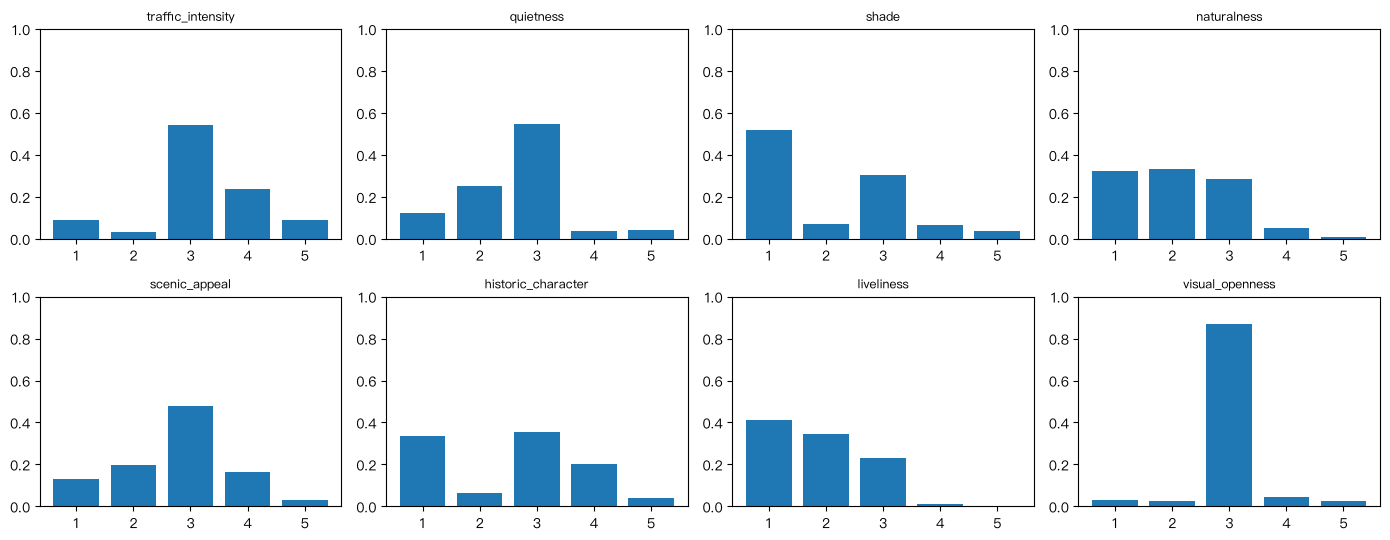

,Mean,Std,Top-level share,Within-cell std,Warning
Dimension,,,,,
traffic_intensity,3.21,0.98,0.54,0.28,
quietness,2.62,0.89,0.55,0.25,
shade,2.03,1.20,0.52,0.44,
naturalness,2.08,0.93,0.33,0.29,
scenic_appeal,2.77,0.98,0.48,0.29,
historic_character,2.54,1.25,0.36,0.38,
liveliness,1.84,0.81,0.41,0.28,
visual_openness,3.00,0.55,0.87,0.15,⚠ low discrimination


In [10]:
fig, axes = plt.subplots(2, 4, figsize=(14, 5.5))
rows = []
for ax, d in zip(axes.ravel(), DIMS):
    vc = ok[d].value_counts(normalize=True).reindex([1, 2, 3, 4, 5]).fillna(0)
    ax.bar(vc.index, vc.values); ax.set_title(d, fontsize=9); ax.set_ylim(0, 1); ax.set_xticks([1, 2, 3, 4, 5])
    rows.append({"Dimension": d, "Mean": ok[d].mean(), "Std": ok[d].std(), "Top-level share": vc.max(),
                 "Within-cell std": agg[f"{d}_std"].mean() if len(agg) else np.nan})
plt.tight_layout(); plt.show()
qc = pd.DataFrame(rows).set_index("Dimension").round(2)
qc["Warning"] = np.where((qc["Top-level share"] > 0.6) | (qc["Std"] < 0.6), "⚠ low discrimination", "")
qc

## 10. Quality check (2): does it agree with the objective data?
A **rough check** with the OSM / WorldCover features computed in 03: places with a high traffic score should have more major road, places with a high shade score should have more trees, and so on.
The expectation is a **moderate correlation in the right direction**; no correlation or the wrong direction means the prompt has a problem. With only a few dozen cells the correlation coefficients are very unstable, so draw conclusions after scaling up.

In [11]:
from scipy.stats import spearmanr

op = path("processed", "osm_features.parquet")
if fs.exists(op):
    osm = read_parquet(op)
    m = labels_cell.merge(osm, on=["cell_id", "h3_index"], how="inner")
    checks = [("traffic_intensity", "road_major_m", +1), ("quietness", "road_major_m", -1),
              ("shade", "wc_tree_frac", +1), ("naturalness", "osm_green_frac", +1),
              ("naturalness", "wc_built_frac", -1), ("visual_openness", "osm_building_frac", -1),
              ("liveliness", "poi_count", +1), ("scenic_appeal", "osm_green_frac", +1)]
    out = []
    for d, f, sign in checks:
        x = m[[d, f]].dropna()
        if len(x) >= 8 and x[d].nunique() > 1 and x[f].nunique() > 1:
            r = spearmanr(x[d], x[f]).correlation
            out.append({"Dimension": d, "Reference feature": f, "Expected sign": "+" if sign > 0 else "−", "Samples": len(x),
                        "Spearman": round(r, 2), "Result": "✓" if r * sign > 0.2 else "✗ check"})
    display(pd.DataFrame(out)) if out else print("Too few cells available for the check")
else:
    print("osm_features.parquet does not exist yet; run 03 first")

,Dimension,Reference feature,Expected sign,Samples,Spearman,Result
0,traffic_intensity,road_major_m,+,1116,0.57,✓
1,quietness,road_major_m,−,1116,-0.59,✓
2,shade,wc_tree_frac,+,1116,0.32,✓
3,naturalness,osm_green_frac,+,1116,0.31,✓
4,naturalness,wc_built_frac,−,1116,-0.56,✓
5,visual_openness,osm_building_frac,−,1116,-0.32,✓
6,liveliness,poi_count,+,1116,0.58,✓
7,scenic_appeal,osm_green_frac,+,1116,0.28,✓


## 11. Export the human annotation sheet (E1: can we trust the VLM labels?)
This is the key step in the whole project for **checking whether the teacher is reliable**:
1. Randomly draw `QA_N` usable photos, copy them to `processed/qa/human_images/`, and generate a blank scoring sheet.
2. **At least 2 team members**, independently and **without seeing Gemini's scores**, rate every photo from 1 to 5 using the anchors in `prompts/{version}.txt` (the same rules, so that the comparison with Gemini is about the same thing).
3. First compute the agreement between humans (ICC or Spearman): if people do not agree with each other, the dimension is poorly defined and the rules should be changed, rather than blaming Gemini.
4. Then compute the Spearman correlation between Gemini and the human mean. **Suggested acceptance line: a dimension enters training only if the correlation is ≥ 0.5.**

Gemini's scores are deliberately not in this sheet, to avoid anchoring bias.

In [12]:
qa_dir = "processed/qa/human_images"
makedirs(path("processed", "qa")); makedirs(path(qa_dir))
pick = ok.drop_duplicates("image_id").merge(sv[["image_id", "image_path"]], on="image_id")
pick = pick.sample(n=min(QA_N, len(pick)), random_state=SEED)

for r in tqdm(list(pick.itertuples()), desc="Copying photos"):
    dst = path(qa_dir, f"{r.image_id}.jpg")
    if not fs.exists(dst):
        with fs.open(path(r.image_path), "rb") as src, fs.open(dst, "wb") as out:
            out.write(src.read())

sheet = pd.DataFrame({"image_id": pick.image_id.values, "file": [f"{qa_dir}/{i}.jpg" for i in pick.image_id],
                      **{d: "" for d in DIMS}, "rater": "", "notes": ""})
with fs.open(path("processed", "qa", "human_label_sheet.csv"), "w") as f:
    sheet.to_csv(f, index=False)
print(f"Exported {len(sheet)} photos and a blank scoring sheet: processed/qa/human_label_sheet.csv")
print("Each rater who scores should copy the sheet and fill in their own name under rater.")

Copying photos:   0%|          | 0/150 [00:00<?, ?it/s]

Exported 150 photos and a blank scoring sheet: processed/qa/human_label_sheet.csv
Each rater who scores should copy the sheet and fill in their own name under rater.


## 12. Run record

In [13]:
manifest = write_manifest({
    "step": "04_labeling", "model": MODEL, "location": LOCATION,
    "prompt_version": PROMPT_VERSION, "prompt_sha": PROMPT_SHA,
    "images_total": int(len(sv)), "images_scored_cached": int(len(mine)),
    "images_failed_this_run": int(len(errors)), "images_usable": int(mine.usable.sum()),
    "cells_total": int(len(labels_cell)), "cells_labeled": int(enough.sum()),
    "input_tokens": meta["input_tokens"], "output_tokens": meta["output_tokens"], "est_cost_usd": meta["est_cost_usd"],
    "outputs": ["processed/labels_image.parquet", "processed/labels_cell.parquet",
                "processed/labels_meta.json", "processed/qa/human_label_sheet.csv"],
    "finished_at": now_iso(),
}, "04_labeling_manifest.json")
print(json.dumps(manifest, indent=2, ensure_ascii=False))

{
  "step": "04_labeling",
  "model": "gemini-2.5-flash",
  "location": "us-central1",
  "prompt_version": "v2",
  "prompt_sha": "f8e50b7d0a03",
  "images_total": 4421,
  "images_scored_cached": 4421,
  "images_failed_this_run": 0,
  "images_usable": 4340,
  "cells_total": 1126,
  "cells_labeled": 1116,
  "input_tokens": 10505072,
  "output_tokens": 557698,
  "est_cost_usd": 4.5458,
  "outputs": [
    "processed/labels_image.parquet",
    "processed/labels_cell.parquet",
    "processed/labels_meta.json",
    "processed/qa/human_label_sheet.csv"
  ],
  "finished_at": "2026-10-13T02:41:50Z"
}


## Next steps
- First tune the scoring rules on a few dozen photos (section 5), then set `MAX_IMAGES` to `None` to score everything.
- Organize human annotation and run **E1** (human-human agreement, human-machine correlation). Which dimensions pass decides which ones are kept in later training.
- **E0 (is street view necessary?)**: use the same rules to let Gemini score the **aerial tile**, and compare with the "street view" result and with the human scores. This needs a separate small notebook that reuses `score_image` from here.
- Next notebook: `05_build_dataset`, which merges X and Y and splits train / val / test by spatial block.